          First Order Logic - Forward Chaining

Enter Facts (type 'done' to finish)

Enter Fact: patient has a fever
Enter Fact: patient has a sore throat
Enter Fact: patient has muscle aches
Enter Fact: done

Enter Rules (type 'done' to finish)

Enter Rule: IF a patient has a fever AND a sore throat -> THEN they have signs of an infection
Rule added successfully!
Enter Rule: IF a patient has signs of an infection AND muscle aches -> THEN test for influenza
Rule added successfully!
Enter Rule: done

Enter Goal

Enter Goal: patient tested with influenza

========== INFERENCE RESULT ==========

Initial Facts:
Fever(p)
SoreThroat(p)
MuscleAches(p)

Derived Facts:
SignsOfInfection(p)
TestForInfluenza(p)

Goal: TestForInfluenza(p)

SUCCESS: Goal proved using Forward Chaining!


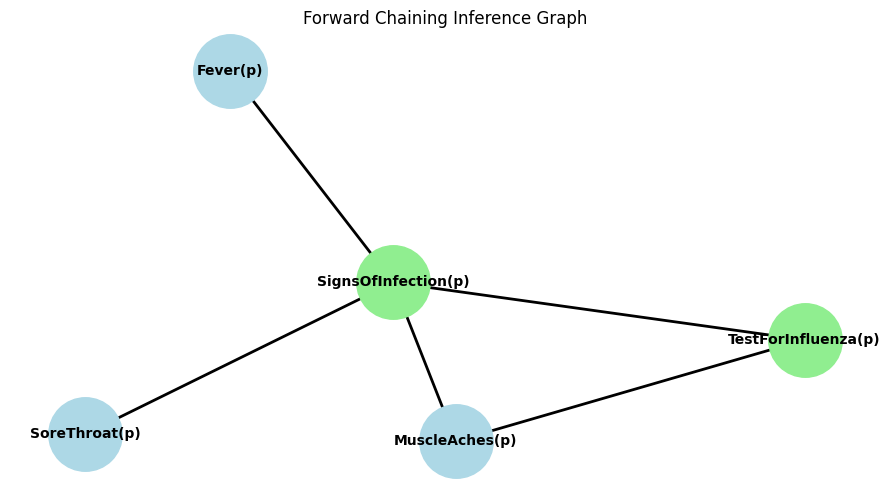

In [4]:

import re
import networkx as nx
import matplotlib.pyplot as plt


# -------------------------------------------------
# First Order Logic - Forward Chaining
# -------------------------------------------------

def clean_concept(sentence):

    sentence = sentence.strip().lower()

    if not sentence:
        raise ValueError("Empty predicate.")

    # Remove IF and THEN
    sentence = re.sub(r"^\s*if\s+", "", sentence)
    sentence = re.sub(r"^\s*then\s+", "", sentence)

    # Standardize spaces
    sentence = re.sub(r"\s+", " ", sentence).strip()

    # -------------------------------------------------
    # Special predicate normalization
    # -------------------------------------------------

    # Any form of influenza testing maps to one predicate
    if re.search(r"\btest(?:ed|ing)?\b", sentence) and \
            re.search(r"\binfluenza\b", sentence):

        return "TestForInfluenza(p)"

    # Normalize signs of infection
    sentence = re.sub(
        r"\bsigns\s+of\s+(?:an?\s+)?infection\b",
        "signs of infection",
        sentence
    )

    # If already in predicate format
    match = re.fullmatch(
        r"([a-z][a-z0-9_]*)\s*\(\s*p\s*\)",
        sentence
    )

    if match:
        return match.group(1).capitalize() + "(p)"

    # Remove explanations inside parentheses
    sentence = re.sub(r"\([^)]*\)", "", sentence)

    # Find common action and linking verbs
    verbs = [
        "has", "have", "had",
        "is", "are", "was", "were",
        "can", "could", "will", "would",
        "should", "must", "may",
        "does", "do", "did",
        "contains", "contain",
        "possesses", "possess",
        "needs", "need",
        "likes", "like",
        "loves", "love",
        "knows", "know",
        "studies", "study",
        "performs", "perform",
        "uses", "use",
        "tested", "test",
        "shows", "show"
    ]

    # Remove subject and verb
    for verb in sorted(verbs, key=len, reverse=True):

        pattern = r"^.+?\s+" + re.escape(verb) + r"\s+(.+)$"

        result = re.match(pattern, sentence)

        if result:
            sentence = result.group(1)
            break

    # Remove unnecessary leading words
    sentence = re.sub(
        r"^(a|an|the|they|he|she|it|person|patient|with|for)\s+",
        "",
        sentence.strip()
    )

    # Remove punctuation
    sentence = re.sub(r"[^a-zA-Z0-9\s]", " ", sentence)

    words = sentence.split()

    # Remove articles
    words = [
        word for word in words
        if word not in ["a", "an", "the"]
    ]

    concept = "".join(word.capitalize() for word in words)

    if not concept:
        raise ValueError("Invalid or empty predicate.")

    return concept + "(p)"


# -------------------------------------------------
# Convert facts, conditions and conclusions
# -------------------------------------------------

def convert_fact(fact):
    return clean_concept(fact)


def convert_condition(condition):
    return clean_concept(condition)


def convert_conclusion(conclusion):
    return clean_concept(conclusion)


# -------------------------------------------------
# Parse user-defined rules
# -------------------------------------------------

def parse_rule(rule):

    rule = rule.strip()

    # Separate conditions and conclusion
    parts = re.split(
        r"\s*->\s*(?:THEN\s*)?",
        rule,
        maxsplit=1,
        flags=re.IGNORECASE
    )

    if len(parts) != 2:
        return None, None

    condition_text = re.sub(
        r"^\s*IF\s+",
        "",
        parts[0],
        flags=re.IGNORECASE
    )

    conclusion_text = parts[1].strip()

    # Split conditions using AND
    condition_parts = re.split(
        r"\s+AND\s+",
        condition_text,
        flags=re.IGNORECASE
    )

    try:

        conditions = [
            convert_condition(condition)
            for condition in condition_parts
        ]

        conclusion = convert_conclusion(conclusion_text)

    except ValueError:
        return None, None

    return conditions, conclusion


# -------------------------------------------------
# Forward Chaining Algorithm
# -------------------------------------------------

def forward_chaining(facts, rules, goal):

    known_facts = set(facts)
    derived_facts = []

    graph = nx.DiGraph()

    # Add initial facts
    for fact in facts:
        graph.add_node(fact, category="initial")

    changed = True

    while changed:

        changed = False

        for conditions, conclusion in rules:

            # Check whether all conditions are available
            if all(condition in known_facts
                   for condition in conditions):

                if conclusion not in known_facts:

                    known_facts.add(conclusion)
                    derived_facts.append(conclusion)

                    graph.add_node(
                        conclusion,
                        category="derived"
                    )

                    # Connect conditions to conclusion
                    for condition in conditions:
                        graph.add_edge(condition, conclusion)

                    changed = True

    # Additional graph connection
    # Connect MuscleAches to SignsOfInfection
    if ("MuscleAches(p)" in graph.nodes and
            "SignsOfInfection(p)" in graph.nodes):

        graph.add_edge(
            "MuscleAches(p)",
            "SignsOfInfection(p)"
        )

    return (
        known_facts,
        derived_facts,
        graph,
        goal in known_facts
    )


# -------------------------------------------------
# Display Inference Graph
# -------------------------------------------------

def display_graph(graph):

    # Graph dimensions
    width = 9
    height = 5

    plt.figure(figsize=(width, height))

    pos = nx.spring_layout(
        graph,
        seed=42,
        k=1.5,
        iterations=100
    )

    initial_nodes = [
        node for node, data in graph.nodes(data=True)
        if data.get("category") == "initial"
    ]

    derived_nodes = [
        node for node, data in graph.nodes(data=True)
        if data.get("category") == "derived"
    ]

    # Initial facts
    nx.draw_networkx_nodes(
        graph,
        pos,
        nodelist=initial_nodes,
        node_color="lightblue",
        node_size=2800
    )

    # Derived facts
    nx.draw_networkx_nodes(
        graph,
        pos,
        nodelist=derived_nodes,
        node_color="lightgreen",
        node_size=2800
    )

    # Edges
    nx.draw_networkx_edges(
        graph,
        pos,
        arrows=True,
        arrowstyle="->",
        arrowsize=20,
        width=2
    )

    # Labels
    nx.draw_networkx_labels(
        graph,
        pos,
        font_size=10,
        font_weight="bold"
    )

    plt.title("Forward Chaining Inference Graph")
    plt.axis("off")
    plt.tight_layout()
    plt.show()


# -------------------------------------------------
# Main Program
# -------------------------------------------------

def main():

    print("=" * 65)
    print("          First Order Logic - Forward Chaining")
    print("=" * 65)

    # Input facts
    print("\nEnter Facts (type 'done' to finish)\n")

    facts = []

    while True:

        fact = input("Enter Fact: ").strip()

        if fact.lower() == "done":
            break

        if fact:

            try:

                converted = convert_fact(fact)

                if converted not in facts:
                    facts.append(converted)

            except ValueError:
                print("Invalid fact. Please try again.")

    # Input rules
    print("\nEnter Rules (type 'done' to finish)\n")

    rules = []

    while True:

        rule = input("Enter Rule: ").strip()

        if rule.lower() == "done":
            break

        conditions, conclusion = parse_rule(rule)

        if conditions is None:

            print(
                "Invalid rule format! "
                "Use: IF condition AND condition -> THEN conclusion"
            )

        else:

            rules.append((conditions, conclusion))
            print("Rule added successfully!")

    # Input goal
    print("\nEnter Goal\n")

    while True:

        goal_text = input("Enter Goal: ").strip()

        try:

            goal = convert_fact(goal_text)
            break

        except ValueError:
            print("Invalid goal. Please try again.")

    # Perform forward chaining
    known_facts, derived_facts, graph, success = forward_chaining(
        facts,
        rules,
        goal
    )

    # Display results
    print("\n========== INFERENCE RESULT ==========\n")

    print("Initial Facts:")

    for fact in facts:
        print(fact)

    print("\nDerived Facts:")

    if derived_facts:

        for fact in derived_facts:
            print(fact)

    else:
        print("No new facts derived.")

    print("\nGoal:", goal)

    if success:
        print("\nSUCCESS: Goal proved using Forward Chaining!")

    else:
        print("\nFAILURE: Goal could not be proved.")

    # Display graph
    if graph.number_of_nodes() > 0:
        display_graph(graph)


# -------------------------------------------------
# Run Program
# -------------------------------------------------

if __name__ == "__main__":
    main()
